In [1]:
# Cài đặt các thư viện cần thiết (chạy trong Google Colab)
!pip install yfinance arch
import pandas as pd
import numpy as np
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
# Thu thập dữ liệu giá BTC-USD cho 425 ngày (365 train + 60 test)
symbol = "BTC-USD"
end_date = datetime(2025, 6, 23)  # Giả sử ngày hiện tại là 23/6/2025
start_date = end_date - timedelta(days=425)  # 425 ngày trước
df = yf.download(symbol, start=start_date, end=end_date, interval="1d")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 985.3/985.3 kB 16.4 MB/s eta 0:00:00


/tmp/ipython-input-1-2508687276.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(symbol, start=start_date, end=end_date, interval="1d")
[*********************100%***********************]  1 of 1 completed


In [2]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2024-04-24,64276.898438,67075.367188,63589.871094,66408.718750,30276655120
2024-04-25,64481.707031,65275.207031,62783.632812,64275.019531,32155786816
2024-04-26,63755.320312,64789.656250,63322.398438,64485.371094,24139372950
2024-04-27,63419.140625,63898.363281,62424.718750,63750.988281,19530783039
2024-04-28,63113.230469,64321.484375,62793.597656,63423.515625,17334827993


In [3]:
print(df.columns)

MultiIndex([( 'Close', 'BTC-USD'),
            (  'High', 'BTC-USD'),
            (   'Low', 'BTC-USD'),
            (  'Open', 'BTC-USD'),
            ('Volume', 'BTC-USD')],
           names=['Price', 'Ticker'])


In [5]:
# Tính lợi nhuận hàng ngày từ giá đóng cửa
df['Return'] = df[('Close', 'BTC-USD')].pct_change() * 100  # Nhân 100 để chuẩn hóa cho GARCH
df = df.dropna()  # Loại bỏ NaN từ phép tính lợi nhuận
df['Return']

,Return
Date,
2024-04-26,-1.126500
2024-04-27,-0.527297
2024-04-28,-0.482363
2024-04-29,1.153309
2024-04-30,-5.019125
...,...
2025-06-18,0.269797
2025-06-19,-0.189772
2025-06-20,-1.313175


In [6]:
# Chia dữ liệu thành tập huấn luyện (365 ngày) và kiểm tra (60 ngày)
train_size = 365
train_data = df['Return'][:train_size]
test_data = df['Return'][train_size:]

In [7]:
# Xây dựng và huấn luyện mô hình GARCH(1,1)
model = arch_model(train_data, vol='Garch', p=1, o=0, q=1, dist='Normal')
results = model.fit(update_freq=5)

Iteration:      5,   Func. Count:     32,   Neg. LLF: 877.6440969797575
Iteration:     10,   Func. Count:     59,   Neg. LLF: 875.0121825753572
Optimization terminated successfully    (Exit mode 0)
            Current function value: 875.0121798389525
            Iterations: 12
            Function evaluations: 68
            Gradient evaluations: 12


In [8]:
# In tóm tắt mô hình để giải thích tham số
print("\nTóm tắt mô hình GARCH(1,1):\n")
print(results.summary())


Tóm tắt mô hình GARCH(1,1):

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -875.012
Distribution:                  Normal   AIC:                           1758.02
Method:            Maximum Likelihood   BIC:                           1773.62
                                        No. Observations:                  365
Date:                Tue, Jun 24 2025   Df Residuals:                      364
Time:                        02:04:51   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.1689      0.13

In [ ]:
# Giải thích tham số
print("\nGiải thích tham số:")
print("- omega (const): Mức biến động cơ bản (nếu nhỏ, biến động cơ bản thấp).")
print("- alpha[1]: Hệ số ARCH, đo lường tác động của cú sốc trước đó.")
print("- beta[1]: Hệ số GARCH, đo lường tính bền vững của biến động.")
print("- Tổng alpha + beta < 1 đảm bảo mô hình ổn định.")


Giải thích tham số:
- omega (const): Mức biến động cơ bản (nếu nhỏ, biến động cơ bản thấp).
- alpha[1]: Hệ số ARCH, đo lường tác động của cú sốc trước đó.
- beta[1]: Hệ số GARCH, đo lường tính bền vững của biến động.
- Tổng alpha + beta < 1 đảm bảo mô hình ổn định.


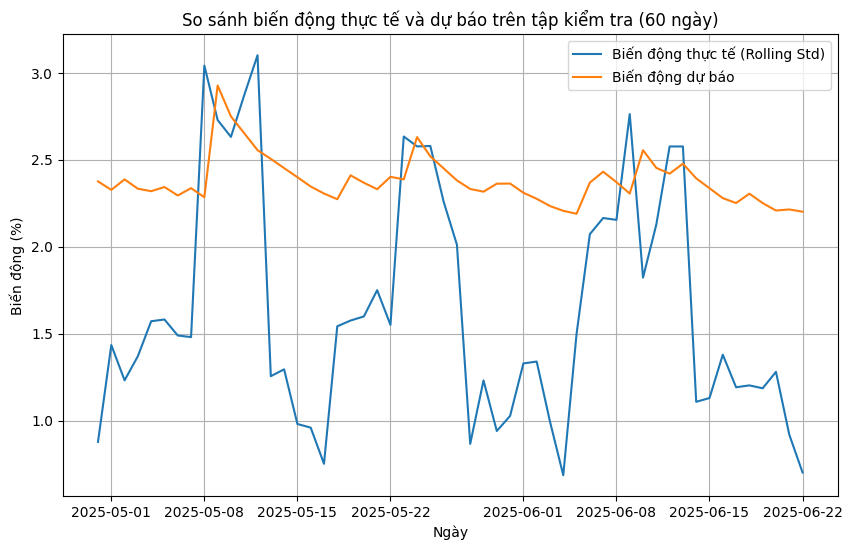

In [9]:
# Tính biến động thực tế trên tập kiểm tra (phương sai lăn)
test_volatility = test_data.rolling(window=5).std().dropna()
# Rolling forecast để dự báo biến động trên tập kiểm tra
volatility_forecast = []
for i in range(len(test_data)):
    # Tạo dữ liệu huấn luyện tạm thời (thêm dữ liệu kiểm tra trước đó)
    temp_data = pd.concat([train_data, test_data[:i]])
    model_temp = arch_model(temp_data, vol='Garch', p=1, o=0, q=1, dist='Normal')
    results_temp = model_temp.fit(disp='off')  # Không hiển thị tiến trình để tăng tốc
    forecast_temp = results_temp.forecast(horizon=1)
    volatility_forecast.append(np.sqrt(forecast_temp.variance.values[-1, -1]))

# Chuyển đổi thành mảng numpy và điều chỉnh độ dài
volatility_forecast = np.array(volatility_forecast)[4:]  # Loại bỏ 4 giá trị đầu do rolling window
forecast_index = test_volatility.index

# Trực quan hóa so sánh biến động thực tế và dự báo
plt.figure(figsize=(10, 6))
plt.plot(forecast_index, test_volatility, label='Biến động thực tế (Rolling Std)')
plt.plot(forecast_index, volatility_forecast, label='Biến động dự báo')
plt.title('So sánh biến động thực tế và dự báo trên tập kiểm tra (60 ngày)')
plt.xlabel('Ngày')
plt.ylabel('Biến động (%)')
plt.legend()
plt.grid(True)
plt.show()

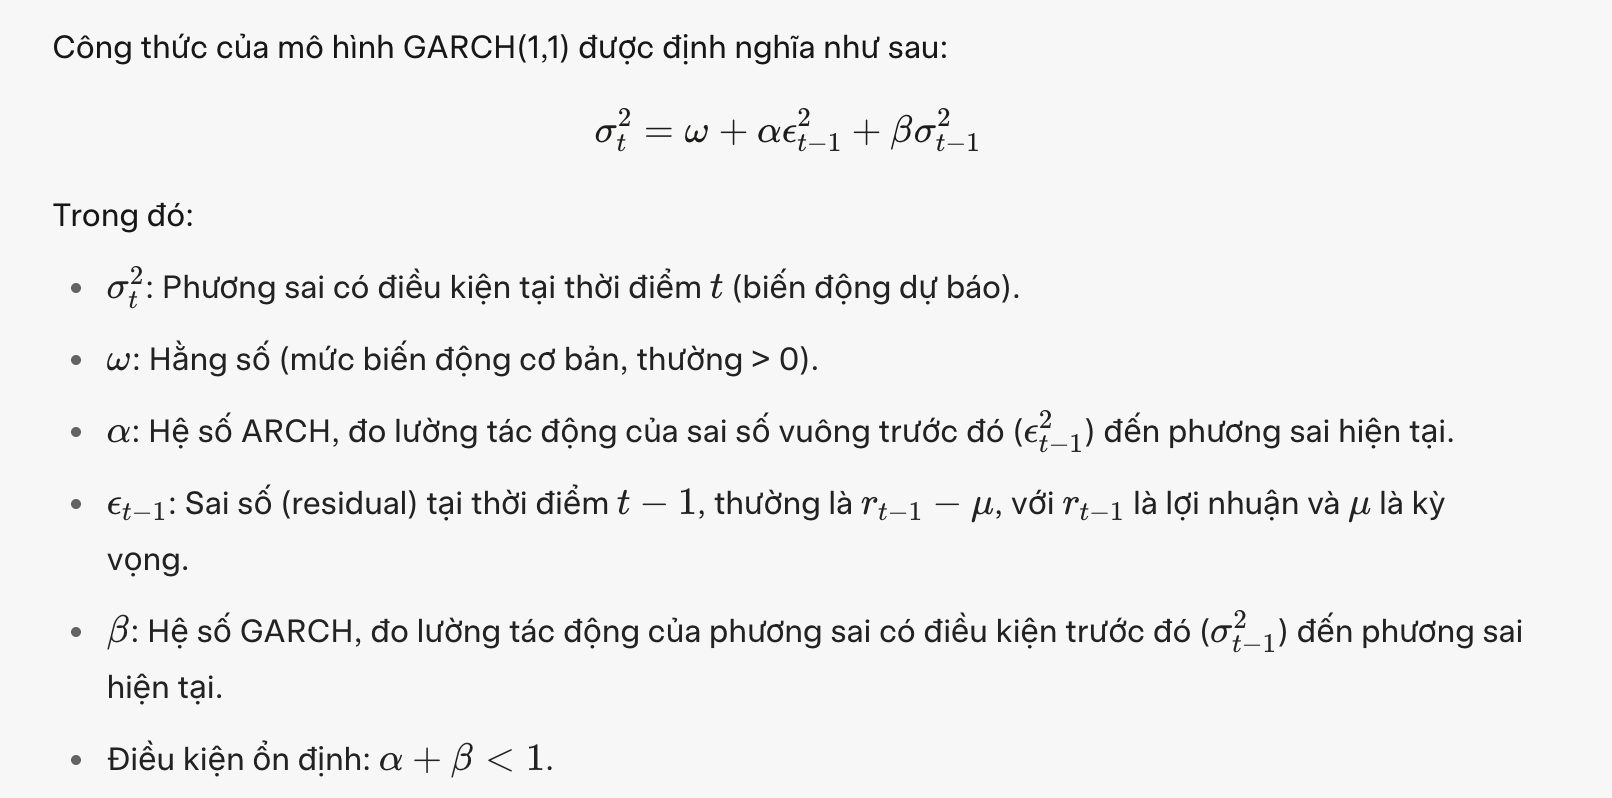

MỤC TIÊU PROJECT : TÌM CÁC HỆ SỐ TƯƠNG ỨNG ĐỂ DỰ ĐOÁN ĐƯỢC BIẾN ĐỘNG DỰ BÁO